## Testlauf mit Jupyter Notebook

In [9]:
# importe und allgemeiner DocString

"""evaluation.py -- Bewertung und Vergleich generierter Peptidsequenzen.

Architektur (nach Torres et al., Eval-Teil):

    SequenceSet   Datencontainer: Name + DataFrame (eine Zeile pro Sequenz)
    Scorer        berechnet Pro-Sequenz-Spalten (ProGen2, ESM-PPPL, APEX, Entropie)
    Evaluator     fuehrt mehrere Scorer aus, mit Cache auf Platte
    Filter        SequenceSet -> SequenceSet (z.B. MIC-Filter)
    Comparison    vergleicht mehrere SequenceSets, liefert Tabelle + Figure

Datenfluss:

    SequenceSet --Evaluator(Scorer...)--> SequenceSet (mit Score-Spalten)
                --Filter--> gefiltertes SequenceSet
                --Comparison({"train":..., "generiert":..., "gefiltert":...})--> ComparisonResult

Vertrag zwischen den Teilen (NICHT ohne Absprache aendern):
    * Pflichtspalte jedes SequenceSet: "sequence" (str, Grossbuchstaben, 20 Standard-AS)
    * Scorer haengen nur Spalten an, sie veraendern oder loeschen keine.
    * Spaltennamen der Scorer (siehe Scorer.columns):
        ppl_progen2   Perplexitaet unter ProGen2 (kleiner = natuerlicher)
        pppl_esm2     Pseudo-Perplexitaet unter ESM2
        mic_apex      vorhergesagte MIC (APEX)
        aa_entropy    Shannon-Entropie der AS-Verteilung der Sequenz (in bit)
"""

from __future__ import annotations

from abc import ABC, abstractmethod
from dataclasses import dataclass, field
from pathlib import Path
from typing import Mapping, Sequence, ClassVar
import hashlib

#Essentielle 
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import numpy as np
import math 
import matplotlib.pyplot as plt

#Transformer
from transformers import AutoModelForCausalLM
from tokenizers import Tokenizer     
import esm     

from aguirre.config import Config
from aguirre.data import read_fasta
from aguirre.helpers import _shannons_H, Akkumulator
cfg = Config()

AMINO_ACIDS = cfg.AS_alphabet

#### Allgemeine DataClass (SequenceSet)
Speichert Sequence Sets mit Namen und DataFrame ein. 


In [8]:
# ---------------------------------------------------------------------------
# 1. Datencontainer
# ---------------------------------------------------------------------------

@dataclass
class SequenceSet:
    """Eine benannte Menge von Sequenzen plus ihre berechneten Eigenschaften.

    Attributes:
        name: Anzeigename, wird in Plots und Tabellen als Gruppenlabel genutzt
            (z.B. "train", "generiert", "gefiltert").
        data: DataFrame mit mindestens der Spalte "sequence". Jede weitere
            Spalte ist eine Pro-Sequenz-Eigenschaft (Scorer-Ausgabe).
    """
    # Verhält sich wie eine __init__
    name: str
    data: pd.DataFrame
    PROTECTED: ClassVar[tuple[str, ...]] = ("sequence", "length")
    
    def __post_init__(self) -> None: #Gut, wenn Sequence fehlt, daher "nach der __init__"
        """Prueft, dass die Spalte "sequence" existiert und nur gueltige AS enthaelt."""
        if "sequence" not in self.data.columns:
            raise ValueError(f"Spalte 'sequence' fehlt, vorhanden: {list(self.data.columns)}")
        seqs = self.data["sequence"]
        if seqs.isna().any() or (seqs == "").any():
            raise ValueError("Leere oder fehlende Sequenzen im Set.")
        invalid = set("".join(seqs)) - set(AMINO_ACIDS)
        if invalid:
            raise ValueError(f"Ungueltige Zeichen in Sequenzen: {sorted(invalid)}")
        self.data = self.data.assign(length=seqs.str.len().astype(int))
        

    @classmethod
    def from_fasta(cls, path: Path, name: str) -> "SequenceSet":
        ids, sequences = read_fasta(path)
        data = pd.DataFrame({"id": ids, "sequence": sequences})
        return cls(name=name, data=data)

    @classmethod
    def from_csv(cls, path: Path, name: str, sequence_col: str = "sequence") -> "SequenceSet":
        data = pd.read_csv(path)
        if sequence_col != "sequence":
            data = data.rename(columns={sequence_col: "sequence"})
        return cls(name=name, data=data)

    def with_columns(self, new_cols: pd.DataFrame) -> "SequenceSet":
        if len(new_cols) != len(self.data):
            raise ValueError("new_cols hat eine andere Zeilenzahl als das Set.")
        # gleiche Spaltennamen werden ueberschrieben (z.B. bei erneutem Evaluator-Lauf)

        verletzt = [c for c in new_cols.columns if c in self.PROTECTED]
        if verletzt:
            raise ValueError(
                f"Geschuetzte Spalten {verletzt} duerfen nicht ueberschrieben werden "
                f"(geschuetzt: {list(self.PROTECTED)})."
            )

        old = self.data.drop(columns=new_cols.columns.intersection(self.data.columns))
        data = pd.concat([old, new_cols.set_axis(old.index)], axis=1)
        return SequenceSet(name=self.name, data=data)
        

    def subset(self, mask: pd.Series, name: str | None = None) -> "SequenceSet":
        if mask.dtype != bool or len(mask) != len(self.data):
            raise ValueError("mask muss ein bool-Series in der Laenge des Sets sein.")
        data = self.data.loc[mask.to_numpy()].reset_index(drop=True)
        return SequenceSet(name=name or self.name, data=data)

#### Scrorer

In [ ]:
class Scorer(ABC):
    """Basisklasse: nimmt Sequenzen, gibt ein DataFrame mit Score-Spalten zurueck.

    Ein Scorer kennt weder Vergleiche noch Plots. Er muss nur wissen, wie man
    aus einer Sequenz eine oder mehrere Zahlen macht.

    Attributes:
        name: eindeutiger Name, dient als Cache-Schluessel (z.B. "progen2").
        columns: Namen der Spalten, die score() zurueckgibt.
    """

    name: str
    columns: list[str]

    @abstractmethod
    def score(self, sequences: Sequence[str]) -> pd.DataFrame:
        """Berechnet die Scores.

        Args:
            sequences: Sequenzen in beliebiger Reihenfolge.

        Returns:
            DataFrame mit len(sequences) Zeilen, gleicher Reihenfolge wie die
            Eingabe und genau den Spalten aus self.columns.
        """


class AminoAcidEntropyScorer(Scorer):
    """Shannon-Entropie der Aminosaeureverteilung pro Sequenz ("Residuenvielfalt").

    H = -sum_a p_a * log2(p_a), p_a = Anteil der AS a in der Sequenz.
    Niedrig = wenige AS dominieren, hoch = gleichmaessig gemischt (max. log2(20)).
    Braucht kein Modell, taugt daher als erster Test der Pipeline.
    """

    name = "aa_entropy"
    columns = ["aa_entropy"]

    def score(self, sequences: Sequence[str]) -> pd.DataFrame:
        H = _shannons_H(sequences)
        return pd.DataFrame({self.columns[0]: H})
            

class ProGen2Scorer(Scorer):
    """Perplexitaet unter ProGen2 (autoregressiv, trainiert auf natuerlichen Proteinen).

    PPL = exp(-1/N * sum_i log p(x_i | x_<i)).  Kleiner = natuerlicher.
    Laeuft auf GPU -> in Batches arbeiten, Modell nur einmal laden.
    """

    name = "progen2"
    columns = ["ppl_progen2"]

    def __init__(self, config: Config): # kein nn.Module, da Kein Training, keine Register Buffer, keine Checkpoints
        """Laedt Modell und Tokenizer (siehe Cluster-Anleitung: Gewichte vorab laden)."""
        super().__init__()
        self.cfg = config
        model = AutoModelForCausalLM.from_pretrained(
        self.cfg.progen_model_name, trust_remote_code=True
        )
        model.eval()
        model.requires_grad_(False)
        tokenizer = Tokenizer.from_pretrained(
            self.cfg.progen_model_name
        )
        self.model = model
        self.tokenizer = tokenizer
        
        #Token-Ids als Attribute
        self.bos_id = self.tokenizer.token_to_id("1")
        self.eos_id = self.tokenizer.token_to_id("2")
        self.pad_id = self.tokenizer.token_to_id("<|pad|>")

        assert self.bos_id is not None, f"ID für BOS nicht gefunden"
        assert self.eos_id is not None, f"ID für EOS nicht gefunden"
        assert self.pad_id is not None, f"ID für Padding-Position nicht gefunden"
        for AS in self.cfg.AS_alphabet:
            if self.tokenizer.token_to_id(AS) is None:
                raise KeyError(
                    f"{AS} aus dem Config-Alphabet {self.cfg.AS_alphabet} hat keine ID im Tokenizer."
                )
            
        self.batch_size = self.cfg.progen_batch_size
        self.device = self.cfg.device
        self.model.to(self.device)
    
    @torch.no_grad()
    def score(self, sequences: Sequence[str]) -> pd.DataFrame:
        ppl_akk = []
        for seq in sequences:
            seq_adapt = "1" + seq + "2" # dim L+2
            encoded_seq = self.tokenizer.encode(seq_adapt).ids # dim L+2
            ids = torch.tensor(encoded_seq, dtype= torch.long, device = self.device).unsqueeze(0) # dim 1, L+2
            logits = self.model(ids).logits # dim 1, L+2, 30
            pred = logits[0,:-2,:] # dim  L, 30
            target = ids[0,1:-1] # 
            CE =F.cross_entropy(pred, target)
            PPL = torch.exp(CE).item()
            ppl_akk.append(PPL)
        return pd.DataFrame({self.columns[0]: ppl_akk})



class ESMPseudoPerplexityScorer(Scorer):
    """Pseudo-Perplexitaet unter ESM2 (maskiertes LM, Salazar et al. 2020).

    Jede Position wird einmal maskiert -> N Forward-Passes pro Sequenz.
    Alle maskierten Varianten einer Sequenz zu einem Batch buendeln.
    Zweitmetrik, weil der Generator selbst ESM2-Embeddings nutzt.
    """

    name = "esm2_pppl"
    columns = ["pppl_esm2"]

    def __init__(self, config: Config) -> None:
        super().__init__()
        self.cfg = config

        mode = cfg.esm_scorer_model_name
        assert mode in ("esm2_t33_650M_UR50D", "esm2_t6_8M_UR50D"), f"Unbekannter Modus '{mode}', erlaubt sind 'esm2_t33_650M_UR50D' und 'esm2_t6_8M_UR50D'"
        #==Auswahl Moden==
        if mode == "esm2_t33_650M_UR50D":
            model,alphabet = esm.pretrained.esm2_t33_650M_UR50D() # Tupel ESM2-Model und Tokentabelle
        elif mode == "esm2_t6_8M_UR50D":
            model, alphabet = esm.pretrained.esm2_t6_8M_UR50D()
        assert model.embed_dim == cfg.embed_dim, f"ESM liefert {model.embed_dim}, Config sagt {cfg.embed_dim}"
        
        model.eval()
        model.requires_grad_(False)
        model.to(self.cfg.device)

        self.batch_converter = alphabet.get_batch_converter()
        self.model = model
        self.mask_idx = alphabet.mask_idx
        self.cls_idx = alphabet.cls_idx
        self.eos_idx = alphabet.eos_idx
        
#Notiz: Das comparison sollte ein csv=True/False einbauen + die benennung der Dateien nach 
# Datensatz_name, Score und Plotart.
    @torch.no_grad #HIER WEITER: Es fehlt das Verständnis + Workflow
    def score(self, sequences: Sequence[str]) -> pd.DataFrame:
        pppl_akk = []
        for seq in sequences:
            
            CE =F.cross_entropy(pred, target)
            PPL = torch.exp(CE).item()
            pppl_akk.append(PPL)
        return pd.DataFrame({self.columns[0]: pppl_akk})        
#

class APEXScorer(Scorer):
    """Vorhergesagte MIC (APEX, Wan et al.).

    Gibt zusaetzlich zu mic_apex ggf. weitere Spalten (z.B. pro Bakterienstamm) zurueck.
    Bei mehreren Staemmen: eine Spalte pro Stamm plus eine Aggregat-Spalte
    "mic_apex" (z.B. geometrisches Mittel), damit MICFilter eine feste Spalte hat.
    """

    name = "apex"
    columns = ["mic_apex"]

    def __init__(self, model_path: Path, device: str = "cuda") -> None:
        raise NotImplementedError

    def score(self, sequences: Sequence[str]) -> pd.DataFrame:
        raise NotImplementedError


### Filter

In [ ]:
class Filter(ABC):
    """Basisklasse fuer Filter. Ein Filter waehlt Sequenzen aus, er berechnet nichts."""

    @abstractmethod
    def apply(self, seqset: SequenceSet) -> SequenceSet:
        """Gibt das gefilterte SequenceSet zurueck (neuer Name, z.B. "<name>_gefiltert")."""

class LengthFilter(Filter):
    """Behaelt Sequenzen mit min_len <= length <= max_len (Spalte "length")."""

    def __init__(self, min_len: int, max_len: int) -> None:
        if min_len > max_len:
            raise ValueError(f"min_len ({min_len}) groesser als max_len ({max_len}).")
        self.min_len = min_len
        self.max_len = max_len

    @classmethod
    def from_config(cls, cfg: Config) -> "LengthFilter":
        return cls(min_len=cfg.pep_min_len, max_len=cfg.pep_max_len)

    def apply(self, seqset: SequenceSet) -> SequenceSet:
        mask = seqset.data["length"].between(self.min_len, self.max_len)
        return seqset.subset(mask, name=f"{seqset.name}_len{self.min_len}-{self.max_len}")

In [ ]:
from tokenizers import Tokenizer
tok = Tokenizer.from_pretrained("hugohrban/progen2-small")

print("Vokabulargröße:", tok.get_vocab_size())
for i in range(tok.get_vocab_size()):
    print(i, repr(tok.id_to_token(i)))

print("IDs von '1' und '2':", tok.token_to_id("1"), tok.token_to_id("2"))
print(tok.encode("1MKTLLV2").ids)

In [ ]:
sc = ProGen2Scorer(cfg)
print(sc.bos_id, sc.eos_id, sc.pad_id)
print(next(sc.model.parameters()).device, sc.model.training)
print(sc.tokenizer.encode("1" + "MKTLLV" + "2").ids)

In [4]:
## Test ProGen2scorer 2
from aguirre.config import TRACKED_DIR

PATH = TRACKED_DIR / "torres_train_sequences.csv"
#Zufallsequenz.
import random 
AS = cfg.AS_alphabet

def zufallssequenz(laenge, alphabet= AS):
    """Baut Sequenz aus länge und Alphabet aus"""
    return "".join(random.choices(AS,k= laenge))

seq_1 = zufallssequenz(laenge= 20)

seq_2 = 20*"A"


human_UBI_seq = "MTVRNIASICNMGTNASALEKDIGPEQFPINEHYFGLVNFGNTCYCNSVLQALYFCRPFRENVLAYKAQQKKKENLLTCLADLFHSIATQKKKVGVIPPKKFISRLRKENDLFDNYMQQDAHEFLNYLLNTIADILQEEKKQEKQNGKLKNGNMNEPAENNKPELTWVHEIFQGTLTNETRCLNCETVSSDEDFLDLSVDVEQNTSITHCLRDFSNTETLCSEQKYYCETCCSKQEAQKRMRVKKLPMILALHLKRFKYMEQLHRYTKLSYRVVFPLELRLFNTSSDAVNLDRMYDLVAVVVHCGSGPNRGHYITIVKSHGFWLLFDDDIVEKIDAQAIEEFYGLTSDISKNSESGYILFYQSRE"
human_Insulin_seq = "MALWMRLLPLLALLALWGPDPAAAFVNQHLCGSHLVEALYLVCGERGFFYTPKTRREAEDLQVGQVELGGGPGAGSLQPLALEGSLQKRGIVEQCCTSICSLYQLENYCN"
torres30 = pd.read_csv(PATH)["sequence"].head(30)

test_seqs = [seq_1, seq_2, human_UBI_seq, human_Insulin_seq]
test_df = pd.DataFrame({"sequence": test_seqs})
test_df = pd.concat(objs=[test_df, torres30], ignore_index= True)
test_list = list(test_df["sequence"])


sc_2 = ProGen2Scorer(config= cfg)
test_scores = sc_2.score(sequences= test_list)

test_df["score"]= test_scores
test_df["laengen"] = test_df["sequence"].str.len()

display(test_df)

config.json: 0.00B [00:00, ?B/s]

configuration_progen.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/hugohrban/progen2-medium:
- configuration_progen.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


modeling_progen.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/hugohrban/progen2-medium:
- modeling_progen.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


model.safetensors:   0%|          | 0.00/3.06G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

,sequence,score,laengen
0,TKSFPGGIELWYDTWAWAWH,27.355028,20
1,AAAAAAAAAAAAAAAAAAAA,2.128292,20
2,MTVRNIASICNMGTNASALEKDIGPEQFPINEHYFGLVNFGNTCYC...,1.708719,365
3,MALWMRLLPLLALLALWGPDPAAAFVNQHLCGSHLVEALYLVCGER...,5.213462,110
4,FFKKWPWWPWRRK,26.752834,13
5,RSVCRQIKICRRRGGCYYLCTNRPY,21.846087,25
6,PKTLRKFFARIRGGRAAVLNALGKEEQIGRASNSGRKCARKKK,17.530945,43
7,SNTALRRYNQWATGHFM,26.882225,17
8,RCICVLGVC,22.231194,9
9,CEWYNISCQLGNKGQWCTLTKECQRSCK,24.693802,28


/var/folders/bd/jt99k0p569j1j60f7kqyhhyr0000gn/T/ipykernel_44817/3890833858.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


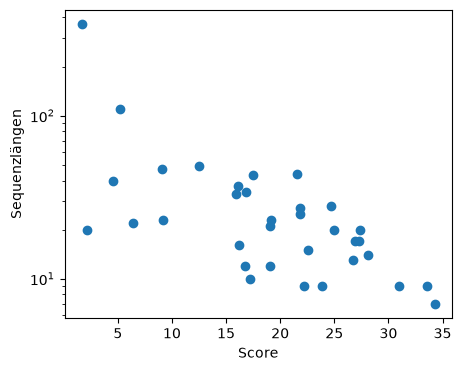

In [5]:
x,y = test_df["score"].to_numpy(), test_df["laengen"].to_numpy()

fig, ax = plt.subplots(1, 1, figsize = (5,4))
ax.scatter(x,y)
ax.set_xlabel("Score")
ax.set_ylabel("Sequenzlängen")
ax.set_yscale("log")
fig.show()